# PaliGemma 2 reads receipts: what does it write when it cannot read?

Companion notebook for the blog post *PaliGemma 2: What Do More Size and More Pixels Buy?*

Runs end to end with **Runtime → Run all**. It downloads the CORD-v2 receipt dataset, runs `paligemma2-3b-mix-224` and `paligemma2-3b-mix-448` on three versions of every receipt, scores the answers and saves tables, charts and example images.

### Before you press Run all (once, about 2 minutes)
1. **Runtime → Change runtime type → T4 GPU.**
2. Open both model pages while logged in to Hugging Face and click **Acknowledge license** (the models are gated):
   * https://huggingface.co/google/paligemma2-3b-mix-224
   * https://huggingface.co/google/paligemma2-3b-mix-448
3. Create a **read** token at https://huggingface.co/settings/tokens and add it in Colab: 🔑 *Secrets* (left sidebar) → name `HF_TOKEN` → paste → turn on *Notebook access*. (If you skip this, the notebook asks you to paste the token.)

### What it measures
| Version | What is done to the receipt |
|---|---|
| `original` | nothing |
| `degraded` | shrunk to 1/4 of its side, blurred, scaled back up: small print becomes unreadable |
| `erased` | every subtotal / tax / total / payment line covered with white boxes: the total is no longer printed |

Prompts: `ocr`, `answer en What is the total amount?`, `answer tr Toplam tutar nedir?`.

Each answer to the total question is labelled:
* **correct**: the true total (on `erased`: *hidden total*, which the model can only get by adding up items, or because the same number is still printed elsewhere)
* **other number**: a number that is printed on the visible receipt, but is not the total
* **invented**: a number that appears **nowhere** on the receipt: the clearest sign of answering from habit instead of from the image
* **abstains**: no number, or a refusal

Runtime: about 45 to 60 minutes for 50 receipts on a T4. Progress is saved after every receipt; if Colab disconnects, just **Run all** again and it continues where it stopped.

In [1]:
#@title Settings
N_RECEIPTS = 50          #@param {type:"integer"}  # CORD-v2 test split has 100; 50 keeps the run under ~1 hour
SAVE_TO_DRIVE = False    #@param {type:"boolean"} # True: results survive the Colab session in MyDrive/paligemma2_receipts
OCR_MAX_NEW_TOKENS = 160 #@param {type:"integer"}
QA_MAX_NEW_TOKENS = 24   #@param {type:"integer"}

MODELS = ['google/paligemma2-3b-mix-224', 'google/paligemma2-3b-mix-448']
PROMPTS = {
    'ocr':      'ocr',
    'total_en': 'answer en What is the total amount?',
    'total_tr': 'answer tr Toplam tutar nedir?',
}
VERSIONS = ['original', 'degraded', 'erased']

In [2]:
#@title Install and log in
!pip -q install -U "transformers>=4.47" accelerate datasets pillow pandas matplotlib tabulate

import os
try:
    from google.colab import userdata
    os.environ['HF_TOKEN'] = userdata.get('HF_TOKEN')
    print('HF token loaded from Colab secrets.')
except Exception:
    from huggingface_hub import notebook_login
    notebook_login()

OUT = '/content/drive/MyDrive/paligemma2_receipts' if SAVE_TO_DRIVE else '/content/paligemma2_receipts'
if SAVE_TO_DRIVE:
    from google.colab import drive; drive.mount('/content/drive')
os.makedirs(OUT, exist_ok=True)
print('Results go to', OUT)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Results go to /content/paligemma2_receipts


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


README.md:   0%|          | 0.00/27.0 [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

data/train-00000-of-00004-b4aaeceff1d90e(…): reconstructing file:   0%|          |  0.00B /  490MB            

data/train-00000-of-00004-b4aaeceff1d90e(…): downloading bytes:           |  0.00B            

...

data/test-00000-of-00001-9c204eb3f4e1179(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/800 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/100 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/100 [00:00<?, ? examples/s]

50 receipts ready (CORD-v2 test split).
Receipts whose total is still printed elsewhere after erasing (e.g. equals an item price): 11


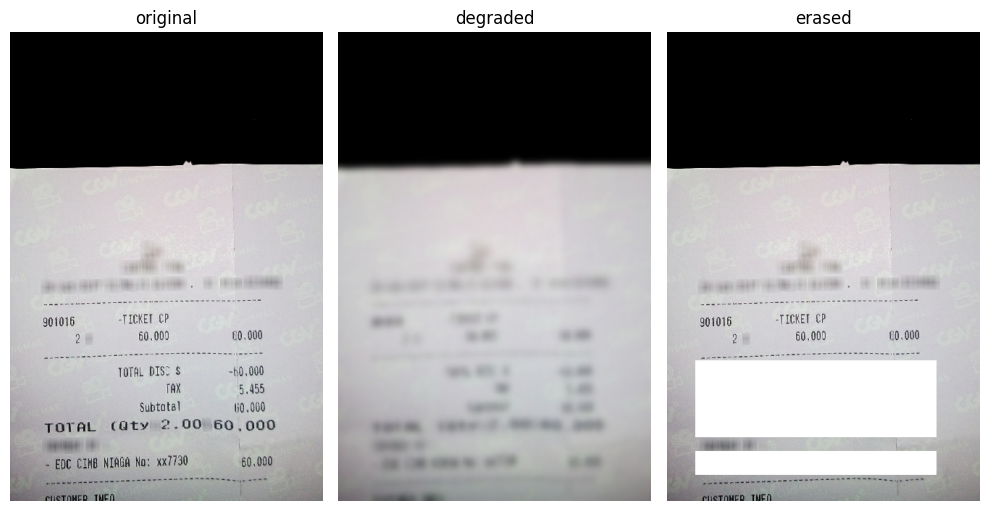

In [3]:
#@title Download CORD-v2 and build the three versions of each receipt
import json, re
from datasets import load_dataset
from PIL import Image, ImageDraw, ImageFilter

ds = load_dataset('naver-clova-ix/cord-v2', split='test')

def digits(s):
    d = re.sub(r'\D', '', str(s)).lstrip('0')
    return d or None

def first(v):
    return v[0] if isinstance(v, list) else v

def quad_box(q, sx, sy):
    xs = [q['x1'], q['x2'], q['x3'], q['x4']]; ys = [q['y1'], q['y2'], q['y3'], q['y4']]
    return min(xs) * sx, min(ys) * sy, max(xs) * sx, max(ys) * sy

receipts = []
for i, ex in enumerate(ds):
    if len(receipts) >= N_RECEIPTS:
        break
    gt = json.loads(ex['ground_truth'])
    total_block = gt['gt_parse'].get('total')
    total_block = first(total_block) if total_block else None
    total = first(total_block.get('total_price')) if isinstance(total_block, dict) else None
    if not digits(total):
        continue                                   # a few receipts have no labelled total
    img = ex['image'].convert('RGB')
    W, H = img.size
    meta = gt['meta']['image_size']
    sx, sy = W / meta['width'], H / meta['height']
    lines = gt['valid_line']
    words = [(w['text'], quad_box(w['quad'], sx, sy), l['category']) for l in lines for w in l['words']]
    hide = [b for t, b, c in words if c.startswith(('total.', 'sub_total.'))]
    if not hide:
        continue
    # erased version: white box over every subtotal / tax / total / payment word, with a margin
    er = img.copy(); dr = ImageDraw.Draw(er); pad = max(3, int(0.006 * max(W, H)))
    # cover whole lines: extend each box to the full width of the receipt text
    x_lo = min(b[0] for _, b, _ in words); x_hi = max(b[2] for _, b, _ in words)
    for b in hide:
        dr.rectangle([x_lo - pad, b[1] - pad, x_hi + pad, b[3] + pad], fill='white')
    # degraded version
    small = img.resize((max(1, W // 4), max(1, H // 4)), Image.BILINEAR).filter(ImageFilter.GaussianBlur(1.0))
    dg = small.resize((W, H), Image.BILINEAR)
    all_nums = {digits(t) for t, _, _ in words if digits(t)}
    visible_after_erase = {digits(t) for t, b, c in words
                           if digits(t) and not c.startswith(('total.', 'sub_total.'))}
    receipts.append(dict(
        idx=i, total=total, total_d=digits(total),
        gt_words=[t for t, _, _ in words],
        nums={'original': all_nums, 'degraded': all_nums, 'erased': visible_after_erase},
        total_still_visible_when_erased=digits(total) in visible_after_erase,
        images={'original': img, 'degraded': dg, 'erased': er}))

print(f'{len(receipts)} receipts ready (CORD-v2 test split).')
print('Receipts whose total is still printed elsewhere after erasing (e.g. equals an item price):',
      sum(r['total_still_visible_when_erased'] for r in receipts))

# save a preview of the three versions for the blog post
import matplotlib.pyplot as plt
r0 = receipts[0]
fig, ax = plt.subplots(1, 3, figsize=(10, 5))
for a, v in zip(ax, VERSIONS):
    a.imshow(r0['images'][v]); a.set_title(v); a.axis('off')
plt.tight_layout(); plt.savefig(f'{OUT}/versions_example.png', dpi=150); plt.show()

In [4]:
#@title Run both models (resumes automatically if interrupted)
import torch, gc, time, pandas as pd
from transformers import PaliGemmaProcessor, PaliGemmaForConditionalGeneration

assert torch.cuda.is_available(), 'No GPU: Runtime → Change runtime type → T4 GPU'
cap = torch.cuda.get_device_capability()
DTYPE = torch.bfloat16 if cap[0] >= 8 else torch.float32   # T4 has no native bf16; float32 is safe and fits in 16 GB
print(torch.cuda.get_device_name(), '→', DTYPE)

RAW = f'{OUT}/outputs_raw.csv'
done = pd.read_csv(RAW, dtype=str, keep_default_na=False) if os.path.exists(RAW) else pd.DataFrame(
    columns=['model', 'idx', 'version', 'prompt', 'output', 'seconds'])
done_keys = set(zip(done.model, done.idx.astype(str), done.version, done.prompt))

for model_id in MODELS:
    tag = model_id.split('-')[-1]
    todo = [(r, v, p) for r in receipts for v in VERSIONS for p in PROMPTS
            if not (v == 'erased' and p == 'ocr') and (tag, str(r['idx']), v, p) not in done_keys]
    if not todo:
        print(model_id, 'already done'); continue
    print(f'Loading {model_id} ({len(todo)} generations to run)')
    model = PaliGemmaForConditionalGeneration.from_pretrained(model_id, torch_dtype=DTYPE, device_map='cuda').eval()
    proc = PaliGemmaProcessor.from_pretrained(model_id)
    t0 = time.time(); buffer = []
    for k, (r, v, p) in enumerate(todo, 1):
        inputs = proc(text=PROMPTS[p], images=r['images'][v], return_tensors='pt').to(DTYPE).to(model.device)
        n = inputs['input_ids'].shape[-1]; t = time.time()
        with torch.inference_mode():
            out = model.generate(**inputs, do_sample=False,
                                 max_new_tokens=OCR_MAX_NEW_TOKENS if p == 'ocr' else QA_MAX_NEW_TOKENS)
        text = proc.decode(out[0][n:], skip_special_tokens=True).strip()
        buffer.append(dict(model=tag, idx=str(r['idx']), version=v, prompt=p, output=text,
                           seconds=f'{time.time() - t:.2f}'))
        if len(buffer) >= 8 or k == len(todo):              # checkpoint to disk
            done = pd.concat([done, pd.DataFrame(buffer)], ignore_index=True); buffer = []
            done.to_csv(RAW, index=False)
        if k % 25 == 0 or k == len(todo):
            el = time.time() - t0
            print(f'  {tag}: {k}/{len(todo)}  elapsed {el / 60:.1f} min, ~{el / k * (len(todo) - k) / 60:.1f} min left')
    del model; gc.collect(); torch.cuda.empty_cache()
print('All generations done.')

Tesla T4 → torch.float32
Loading google/paligemma2-3b-mix-224 (400 generations to run)


config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/75.1k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

...

  448: 350/400  elapsed 19.7 min, ~2.8 min left


[transformers] You are passing both `text` and `images` to `PaliGemmaProcessor`. The processor expects special image tokens in the text, as many tokens as there are images per each text. It is recommended to add `<image>` tokens in the very beginning of your text. For this call, we will infer how many images each text has and add special tokens.
[transformers] You are passing both `text` and `images` to `PaliGemmaProcessor`. The processor expects special image tokens in the text, as many tokens as there are images per each text. It is recommended to add `<image>` tokens in the very beginning of your text. For this call, we will infer how many images each text has and add special tokens.
[transformers] You are passing both `text` and `images` to `PaliGemmaProcessor`. The processor expects special image tokens in the text, as many tokens as there are images per each text. It is recommended to add `<image>` tokens in the very beginning of your text. For this call, we will infer how many i

  448: 375/400  elapsed 21.0 min, ~1.4 min left


[transformers] You are passing both `text` and `images` to `PaliGemmaProcessor`. The processor expects special image tokens in the text, as many tokens as there are images per each text. It is recommended to add `<image>` tokens in the very beginning of your text. For this call, we will infer how many images each text has and add special tokens.
[transformers] You are passing both `text` and `images` to `PaliGemmaProcessor`. The processor expects special image tokens in the text, as many tokens as there are images per each text. It is recommended to add `<image>` tokens in the very beginning of your text. For this call, we will infer how many images each text has and add special tokens.
[transformers] You are passing both `text` and `images` to `PaliGemmaProcessor`. The processor expects special image tokens in the text, as many tokens as there are images per each text. It is recommended to add `<image>` tokens in the very beginning of your text. For this call, we will infer how many i

  448: 400/400  elapsed 22.4 min, ~0.0 min left
All generations done.


In [5]:
#@title Score
from collections import Counter
raw = pd.read_csv(RAW, dtype=str, keep_default_na=False)
R = {str(r['idx']): r for r in receipts}
raw = raw[raw.idx.isin(R)]

REFUSAL = re.compile(r"unanswerable|cannot|can't|not (visible|readable|shown)|unknown|no total|okunam|bilinm|görünm|belirsiz", re.I)
NUM = re.compile(r'\d[\d.,]*')

def norm_word(w):
    return re.sub(r'[^\w]', '', str(w).lower())

def word_recall(gt_words, output):
    gt = [norm_word(w) for w in gt_words if norm_word(w)]
    have = Counter(norm_word(w) for w in str(output).split() if norm_word(w))
    hit = 0
    for w in gt:
        if have[w] > 0:
            hit += 1; have[w] -= 1
    return hit / len(gt) if gt else None

def numbers(output):
    s = str(output)  # skip percentages such as a '(10%)' tax rate
    return [d for d in (digits(m.group()) for m in NUM.finditer(s) if not s[m.end():].lstrip().startswith('%')) if d]

def label_total(output, r, version):
    nums = numbers(output)
    if not nums or REFUSAL.search(str(output)):
        return 'abstains'
    if r['total_d'] in nums:
        return 'correct'
    if any(n in r['nums'][version] for n in nums):
        return 'other number'
    return 'invented'

def score(row):
    r = R[row.idx]
    if row.prompt == 'ocr':
        return pd.Series({'word_recall': word_recall(r['gt_words'], row.output), 'label': ''})
    return pd.Series({'word_recall': None, 'label': label_total(row.output, r, row.version)})

scored = pd.concat([raw.reset_index(drop=True), raw.reset_index(drop=True).apply(score, axis=1)], axis=1)
scored['true_total'] = scored.idx.map(lambda i: R[i]['total'])
scored.to_csv(f'{OUT}/outputs_scored.csv', index=False)

LABELS = ['correct', 'other number', 'invented', 'abstains']
# On erased receipts, drop the ones whose total is still printed elsewhere (e.g. a single item costing the total):
# there, writing the total is honest reading, not a guess.
leaky = {str(r['idx']) for r in receipts if r['total_still_visible_when_erased']}
scored['in_table'] = ~((scored.version == 'erased') & scored.idx.isin(leaky))
scored.to_csv(f'{OUT}/outputs_scored.csv', index=False)
qa_rows = scored[(scored.prompt != 'ocr') & scored.in_table]
ocr = (scored[scored.prompt == 'ocr'].groupby(['version', 'model']).word_recall.mean() * 100).round(1).rename('OCR word recall %')
qa = qa_rows.groupby(['version', 'model']).label.value_counts().unstack(fill_value=0)
qa = qa.reindex(columns=LABELS, fill_value=0)
table = pd.concat([ocr, qa], axis=1).reindex(VERSIONS, level=0)
table.to_csv(f'{OUT}/summary_table.csv')

n = len(receipts)
print(f'N = {n} receipts (CORD-v2 test). Total question asked in English and Turkish, so original/degraded rows count {2 * n} answers.')
print(f'Erased rows use the {n - len(leaky)} receipts whose total is printed nowhere else ({2 * (n - len(leaky))} answers); '
      f'{len(leaky)} receipts were left out because the total still appears, e.g. as an item price.')
print('On erased receipts, "correct" = the model produced the hidden total (only possible by adding up the items).\n')
print(table.fillna('–').to_markdown())

print('\nBy question language:')
print(qa_rows.groupby(['version', 'model', 'prompt']).label.value_counts()
      .unstack(fill_value=0).reindex(columns=LABELS, fill_value=0).to_markdown())

N = 50 receipts (CORD-v2 test). Total question asked in English and Turkish, so original/degraded rows count 100 answers.
Erased rows use the 39 receipts whose total is printed nowhere else (78 answers); 11 receipts were left out because the total still appears, e.g. as an item price.
On erased receipts, "correct" = the model produced the hidden total (only possible by adding up the items).

|                     | OCR word recall %   |   correct |   other number |   invented |   abstains |
|:--------------------|:--------------------|----------:|---------------:|-----------:|-----------:|
| ('original', '224') | 52.1                |        44 |              8 |         48 |          0 |
| ('original', '448') | 86.2                |        79 |             11 |          9 |          1 |
| ('degraded', '224') | 13.2                |        14 |              1 |         49 |         36 |
| ('degraded', '448') | 23.0                |        26 |              2 |         35 |         37 |

/tmp/ipykernel_946/3581634021.py:64: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  print(table.fillna('–').to_markdown())


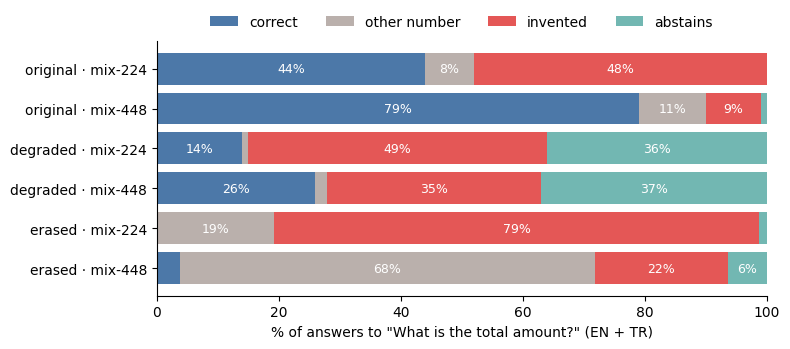

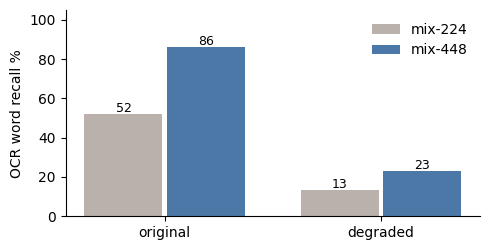

In [6]:
#@title Charts for the blog post
import matplotlib.pyplot as plt, numpy as np
colors = {'correct': '#4C78A8', 'other number': '#BAB0AC', 'invented': '#E45756', 'abstains': '#72B7B2'}
qa_share = qa.div(qa.sum(axis=1), axis=0) * 100
rows = [(v, m) for v in VERSIONS for m in ['224', '448'] if (v, m) in qa_share.index]
fig, ax = plt.subplots(figsize=(8, 3.6))
left = np.zeros(len(rows))
for lab in LABELS:
    vals = np.array([qa_share.loc[rw, lab] for rw in rows])
    ax.barh(range(len(rows)), vals, left=left, color=colors[lab], label=lab)
    for y, (l, w) in enumerate(zip(left, vals)):
        if w >= 6: ax.text(l + w / 2, y, f'{w:.0f}%', ha='center', va='center', color='white', fontsize=9)
    left += vals
ax.set_yticks(range(len(rows))); ax.set_yticklabels([f'{v} · mix-{m}' for v, m in rows]); ax.invert_yaxis()
ax.set_xlim(0, 100); ax.set_xlabel('% of answers to "What is the total amount?" (EN + TR)')
ax.legend(ncol=4, loc='lower center', bbox_to_anchor=(0.5, 1.0), frameon=False)
for s in ['top', 'right']: ax.spines[s].set_visible(False)
plt.tight_layout(); plt.savefig(f'{OUT}/total_answers.png', dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(5, 2.6))
o = ocr.reset_index()
for k, m in enumerate(['224', '448']):
    s = o[o.model == m].set_index('version').reindex(['original', 'degraded'])['OCR word recall %']
    ax.bar(np.arange(2) + k * 0.38, s.values, width=0.36, label=f'mix-{m}', color=['#BAB0AC', '#4C78A8'][k])
    for x, val in zip(np.arange(2) + k * 0.38, s.values): ax.text(x, val + 1, f'{val:.0f}', ha='center', fontsize=9)
ax.set_xticks(np.arange(2) + 0.19); ax.set_xticklabels(['original', 'degraded']); ax.set_ylim(0, 105)
ax.set_ylabel('OCR word recall %'); ax.legend(frameon=False)
for s in ['top', 'right']: ax.spines[s].set_visible(False)
plt.tight_layout(); plt.savefig(f'{OUT}/ocr_recall.png', dpi=200); plt.show()

79 invented answers on erased receipts


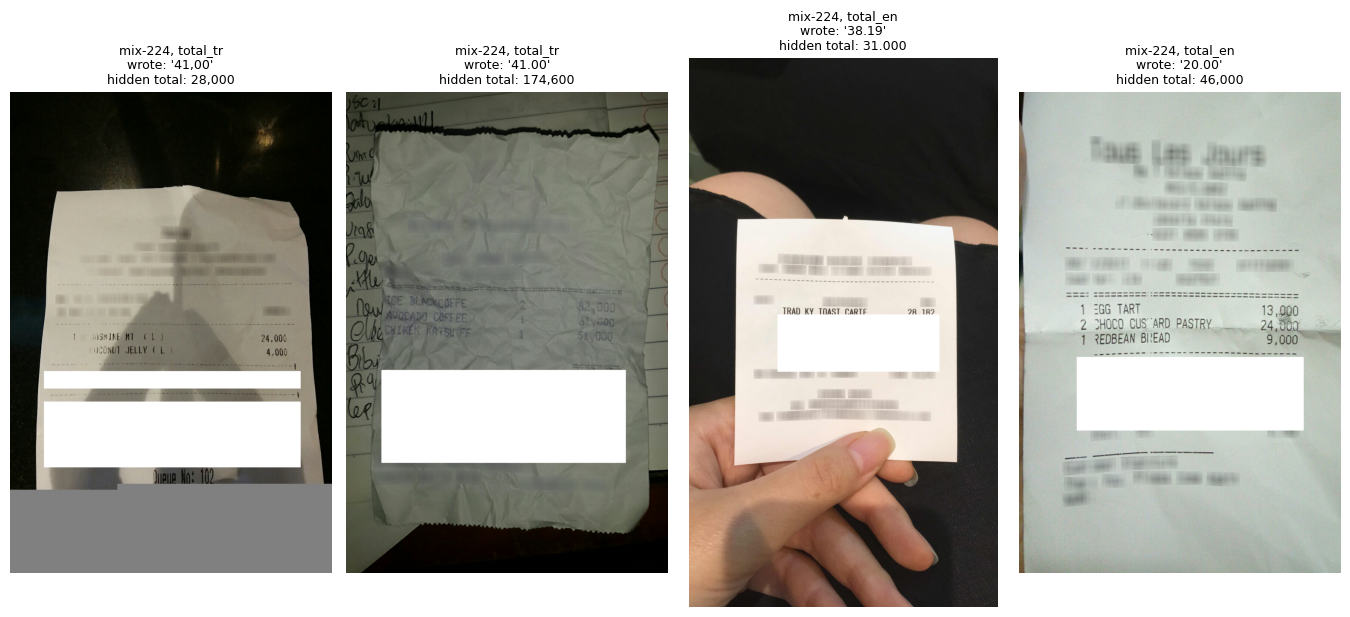

receipt   2 | mix-224 | total_tr | wrote '41,00'                        | hidden total 28,000
receipt   4 | mix-224 | total_tr | wrote '41.00'                        | hidden total 174,600
receipt   5 | mix-224 | total_en | wrote '38.19'                        | hidden total 31.000
receipt   5 | mix-224 | total_tr | wrote '39,187'                       | hidden total 31.000
receipt   6 | mix-224 | total_en | wrote '20.00'                        | hidden total 46,000
receipt   6 | mix-224 | total_tr | wrote '23.00'                        | hidden total 46,000
receipt   7 | mix-224 | total_en | wrote '100.00'                       | hidden total 111,000
receipt   7 | mix-224 | total_tr | wrote '109,00'                       | hidden total 111,000
receipt   8 | mix-224 | total_en | wrote '45.45'                        | hidden total 50,000
receipt   8 | mix-224 | total_tr | wrote '45.45'                        | hidden total 50,000
receipt  13 | mix-224 | total_en | wrote '40,000'        

In [7]:
#@title The most convincing evidence: erased receipts with invented totals
inv = scored[(scored.version == 'erased') & (scored.label == 'invented') & scored.in_table]
print(len(inv), 'invented answers on erased receipts')
show = inv.drop_duplicates('idx').head(4)
if len(show):
    fig, ax = plt.subplots(1, len(show), figsize=(3.4 * len(show), 6))
    ax = np.atleast_1d(ax)
    for a, row in zip(ax, show.itertuples()):
        a.imshow(R[row.idx]['images']['erased']); a.axis('off')
        a.set_title(f'mix-{row.model}, {row.prompt}\nwrote: {row.output[:28]!r}\nhidden total: {row.true_total}', fontsize=9)
    plt.tight_layout(); plt.savefig(f'{OUT}/invented_examples.png', dpi=200); plt.show()
for row in inv.head(12).itertuples():
    print(f'receipt {row.idx:>3} | mix-{row.model} | {row.prompt} | wrote {row.output!r:30} | hidden total {row.true_total}')

In [8]:
#@title Download everything
!cd {OUT}/.. && zip -qr paligemma2_receipts_results.zip {os.path.basename(OUT)}
try:
    from google.colab import files
    files.download(f'{os.path.dirname(OUT)}/paligemma2_receipts_results.zip')
except Exception as e:
    print('Download manually from the Files panel:', e)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Notes for the write-up
* Dataset: CORD-v2 test split (Park et al., 2019), Indonesian receipts, CC BY 4.0. The receipts are not Turkish; the Turkish part of the test is the question language (`answer tr`).
* The *mix* checkpoints are Google's multi-task fine-tunes, tested as released, not the paper's per-task fine-tuned models.
* Automatic labels are a first pass: skim `outputs_scored.csv`, especially the `invented` rows, before quoting numbers.
* With N = 50 report counts and examples; differences of a few answers are noise.